# Lab 06: review of completed experiments

Seed **2473986**. The models trained in Colab on 25 October 2026. This notebook executes analysis of their uploaded records. It does not rerun training or invent training-cell outputs. Its code cells were executed sequentially with Python while assembling this notebook. The original training log and histories are in `results/`. The separate `Lab06.ipynb` provides the training workflow.

Run all cells from this folder. Only the Python standard library and the local `lab06.py` are needed for verification. Plot attachments preserve the supplied PNGs.

In [1]:
from pathlib import Path
import json
from verify_results import verify
ROOT = Path.cwd()
assert (ROOT / 'results' / 'protocol.json').is_file(), 'Open from LAB06_Model_Selection'
evaluations = verify(ROOT / 'results')


mobilenetv2: validation/test metrics, threshold and latency mean verified
efficientnetb0: validation/test metrics, threshold and latency mean verified
yolov8n: validation/test metrics, threshold and latency mean verified
yolov8s: validation/test metrics, threshold and latency mean verified
Split: 1260 / 270 / 270 images, 210 / 45 / 45 source documents
No source ID or recorded image hash crosses partition boundaries
Validation-only selection reproduced: yolov8n
Scope: saved records verified. Image and checkpoint bytes are external.


## Final test metrics

The positive class is bad. The shared threshold is 0.5. Accuracy alone does not describe missed defects.

In [2]:
print(f"{'Model':18s} {'Accuracy':>9s} {'Precision':>10s} {'Recall':>9s} {'F1 bad':>9s} {'Misses':>7s}")
for e in evaluations:
    t=e['test']
    print(f"{e['model']:18s} {t['accuracy']:9.4f} {t['precision_bad']:10.4f} {t['recall_bad']:9.4f} {t['f1_bad']:9.4f} {t['confusion_matrix'][1][0]:7d}")


Model               Accuracy  Precision    Recall    F1 bad  Misses
mobilenetv2           0.9963     1.0000    0.9926    0.9963       1
efficientnetb0        0.9889     1.0000    0.9778    0.9888       3
yolov8n               0.9889     1.0000    0.9778    0.9888       3
yolov8s               0.9926     1.0000    0.9852    0.9925       2


### Test confusion matrices

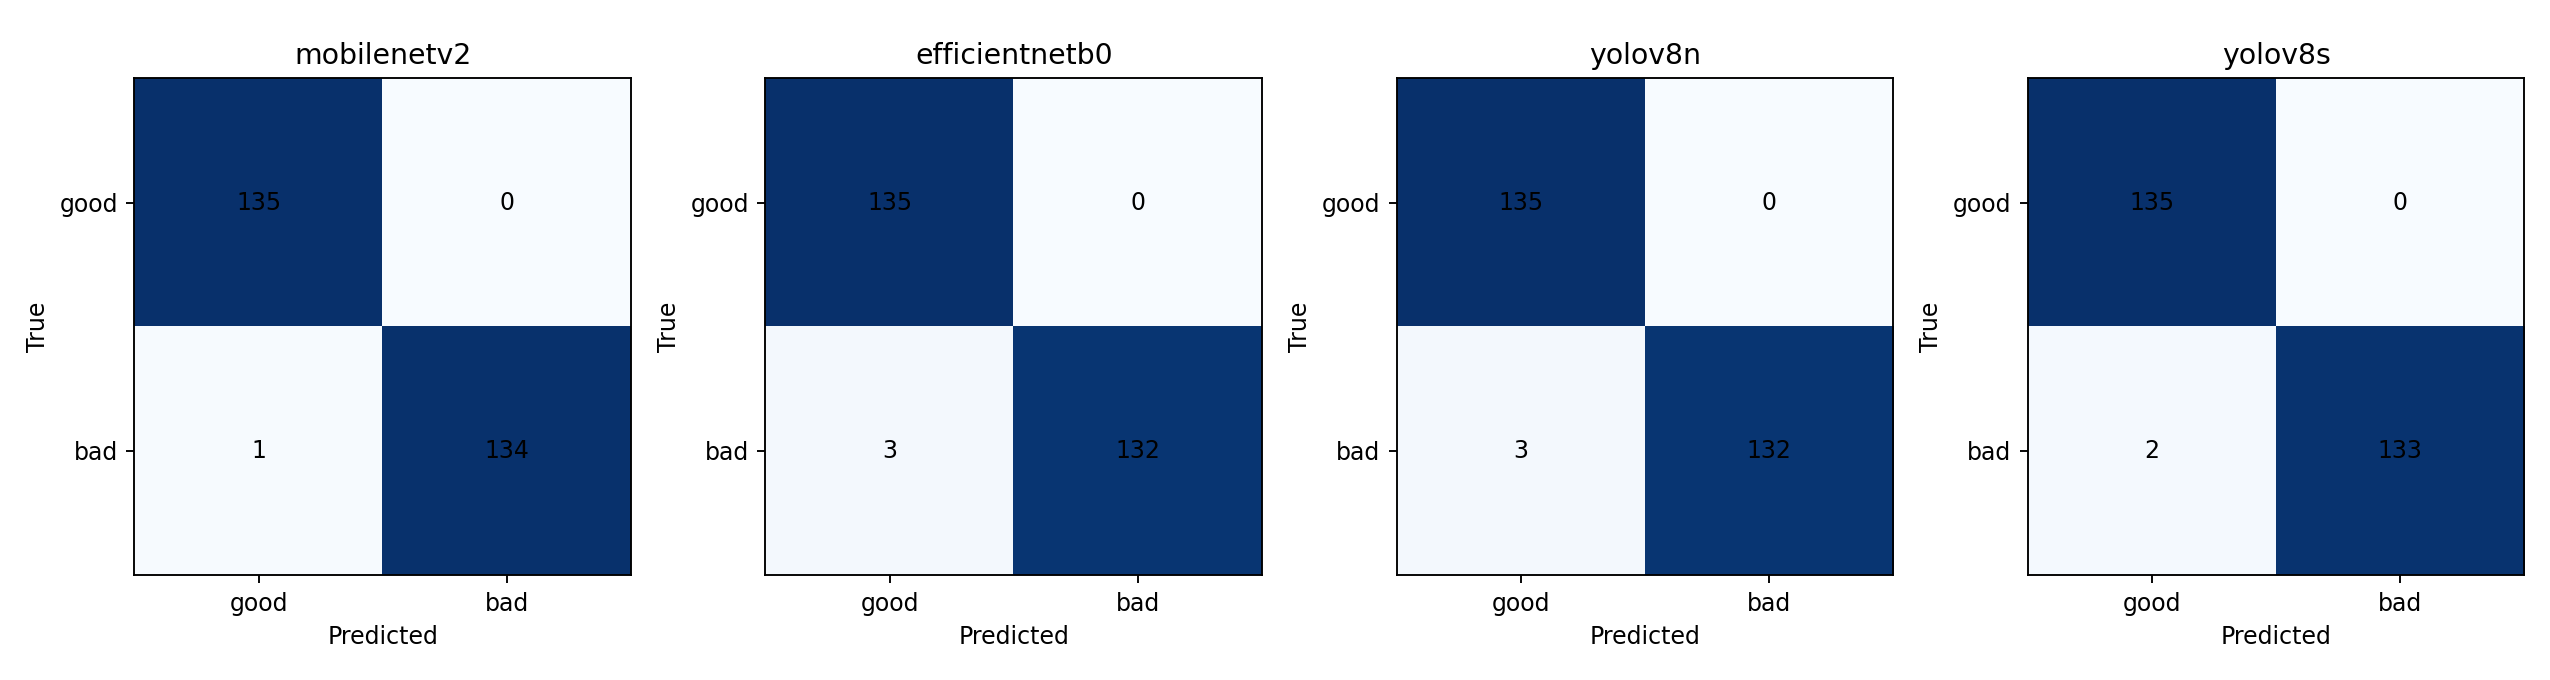

## Cost and selection

The decision uses validation metrics and cost. CPU timings include preprocessing and inference on decoded images in RAM, with 20 warm-ups and 100 timed calls at batch one.

In [3]:
from lab06 import qualifies
config=json.loads((ROOT/'results/protocol.json').read_text())['config']
for e in evaluations:
    print(f"{e['model']:18s} mean={e['latency_ms']:.2f} ms  p95={e['latency_p95_ms']:.2f} ms  size={e['artifact_mib']:.2f} MiB  validation/cost pass={qualifies(e,config['acceptance'])}")
print('Decision:',json.loads((ROOT/'results/decision.json').read_text()))


mobilenetv2        mean=37.69 ms  p95=47.82 ms  size=11.06 MiB  validation/cost pass=True
efficientnetb0     mean=56.69 ms  p95=71.87 ms  size=18.14 MiB  validation/cost pass=False
yolov8n            mean=26.97 ms  p95=32.05 ms  size=2.83 MiB  validation/cost pass=True
yolov8s            mean=51.07 ms  p95=59.62 ms  size=9.78 MiB  validation/cost pass=False
Decision: {'candidate': 'yolov8n', 'validation_acceptance_passed': True, 'test_acceptance_passed': True, 'selection_data': 'validation only'}


### Accuracy and CPU cost

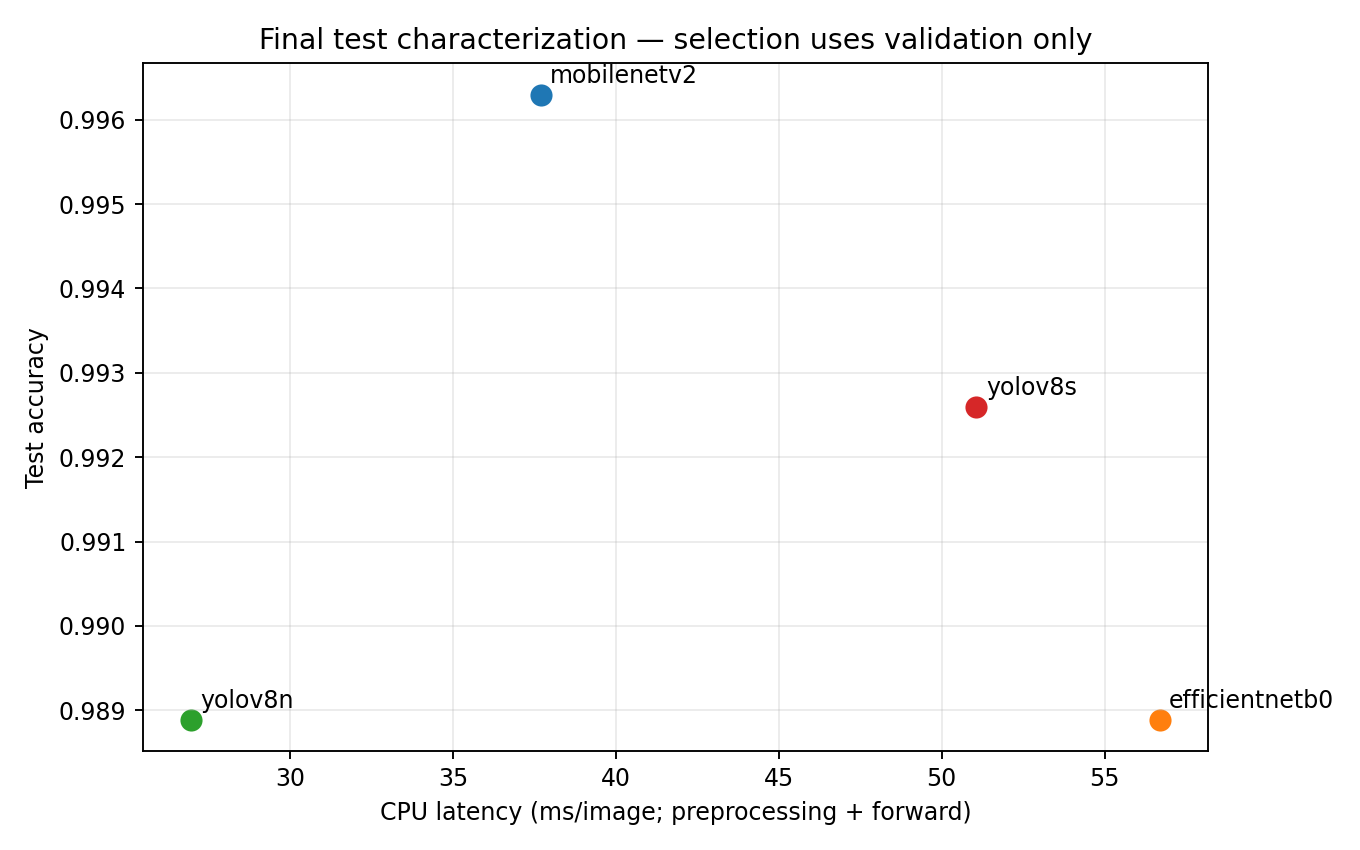

## Learning curves

MobileNetV2 shows decreasing losses with validation fluctuations. EfficientNetB0 has unstable late validation loss and uses its best epoch-11 checkpoint. YOLO selects checkpoints by validation fitness. Its top-5 score is uninformative with two classes.

### mobilenetv2

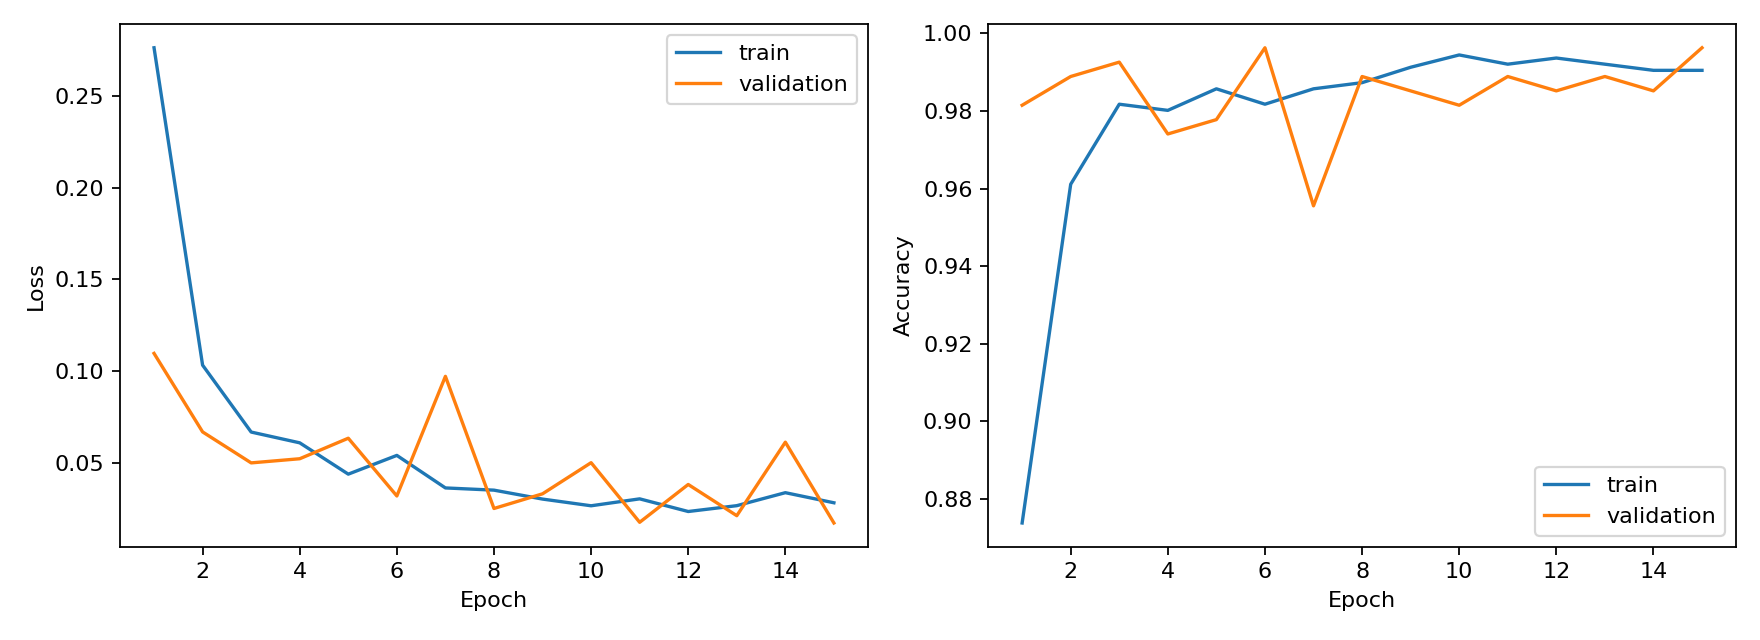

### efficientnetb0

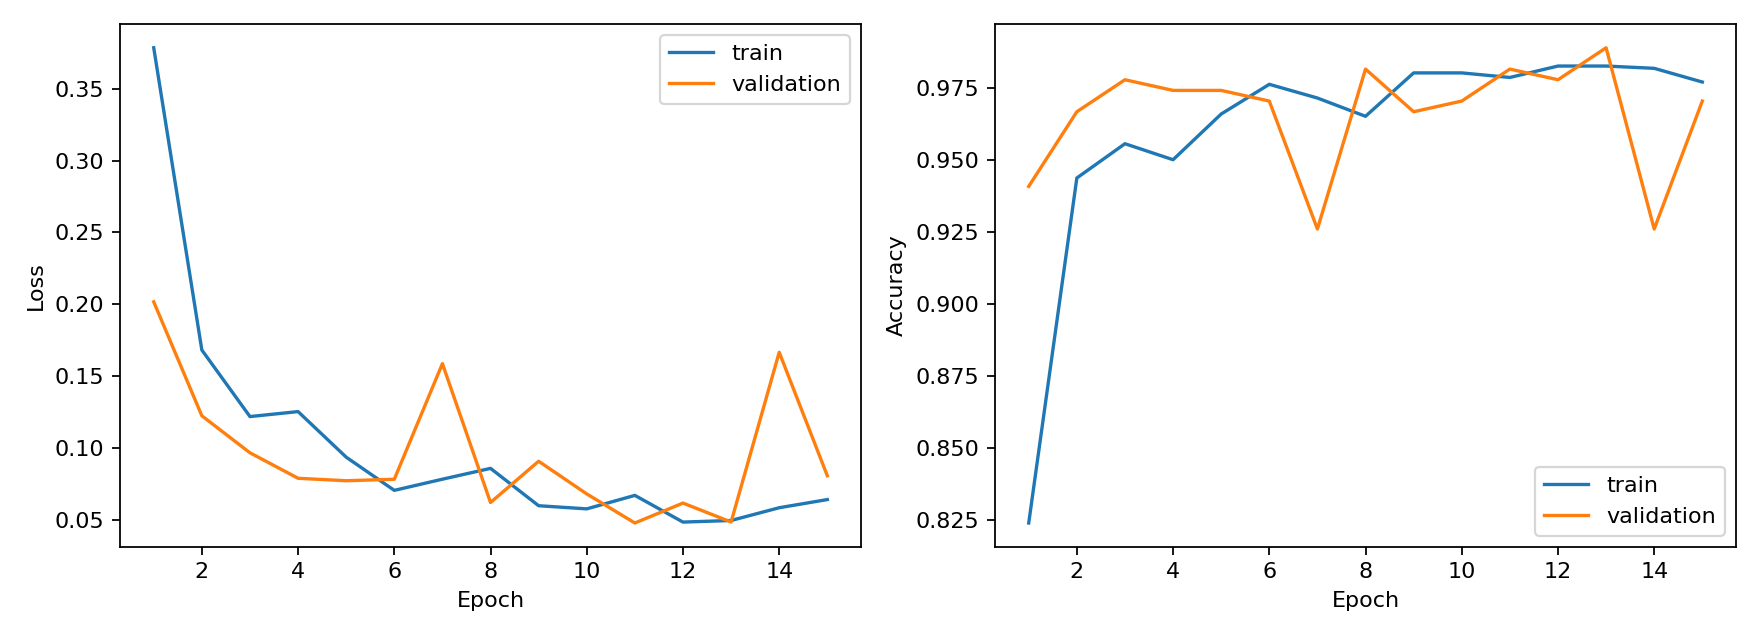

### yolov8n

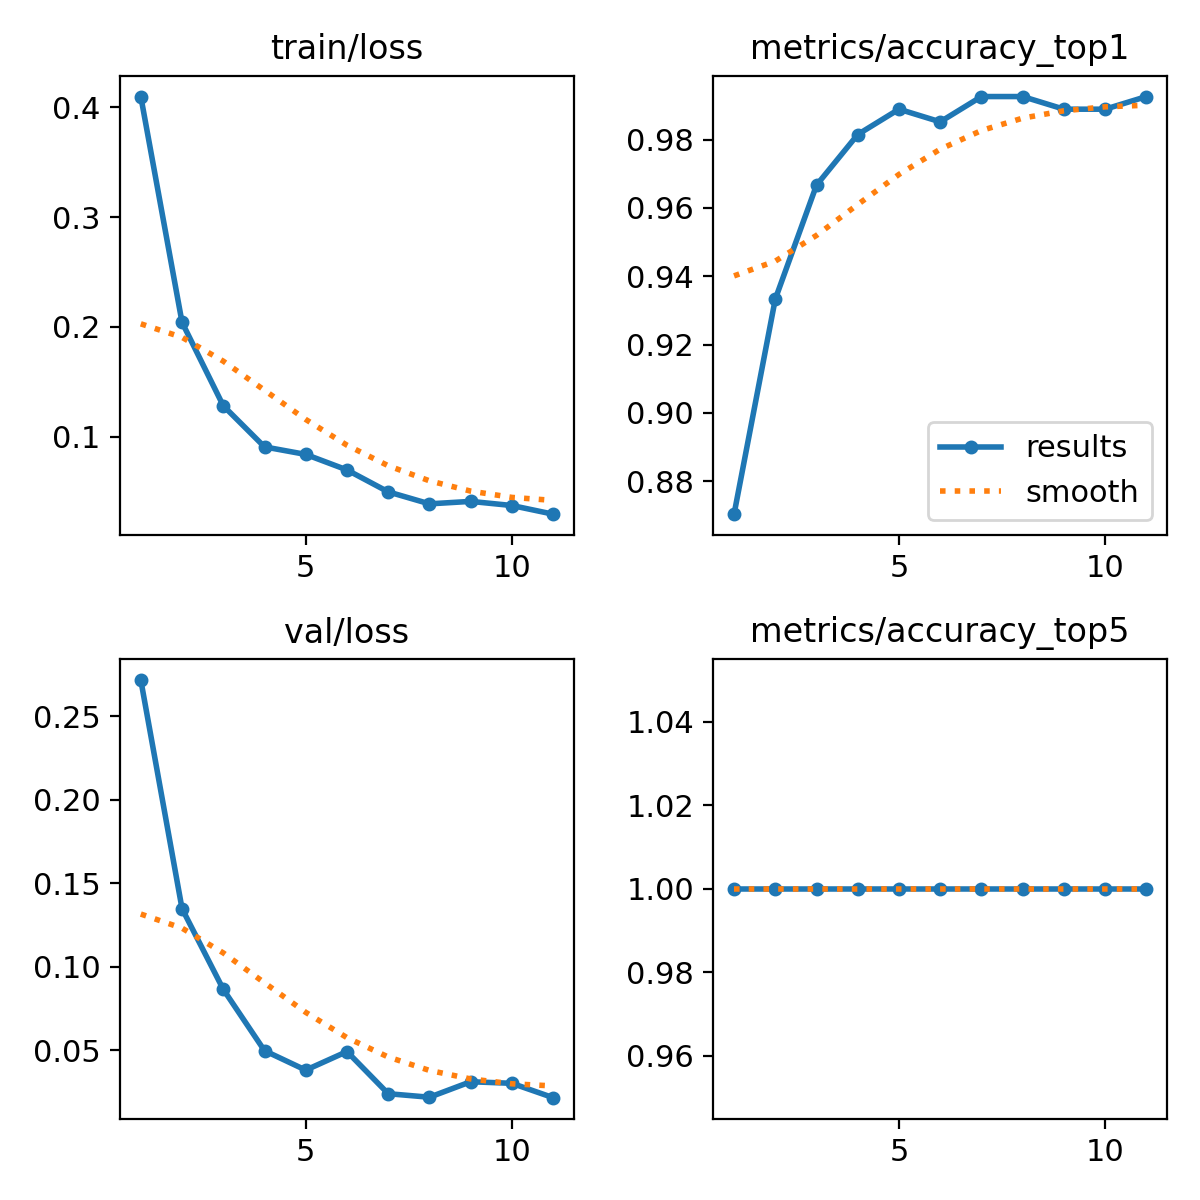

### yolov8s

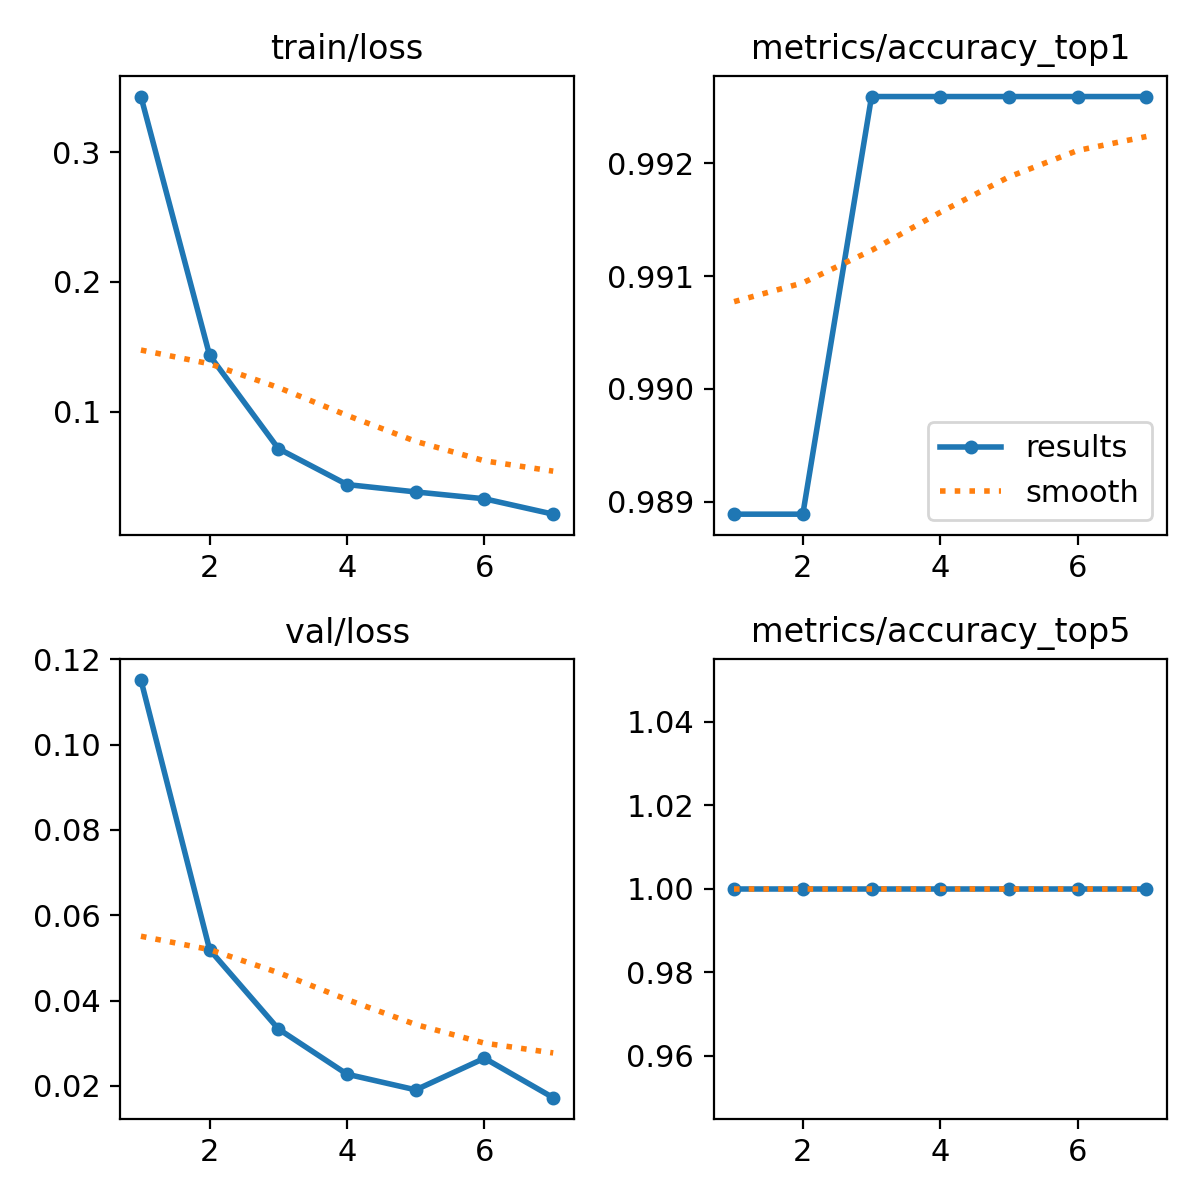

## Errors by defect

All observed test mistakes are false accepts in the glare category. Small subset supports and synthetic generation limit generalization.

In [4]:
import csv
for row in csv.DictReader((ROOT/'results/defect_analysis.csv').open()):
    if row['model']=='yolov8n':
        print(f"{row['defect']:12s} n={row['n']:>2s}  missed bad={row['missed_bad']}  recall={float(row['recall']):.4f}")


blur         n=29  missed bad=0  recall=1.0000
exposure     n=27  missed bad=0  recall=1.0000
glare        n=28  missed bad=3  recall=0.8929
occlusion    n=26  missed bad=0  recall=1.0000
skew         n=25  missed bad=0  recall=1.0000


### Selected model: actual false accepts

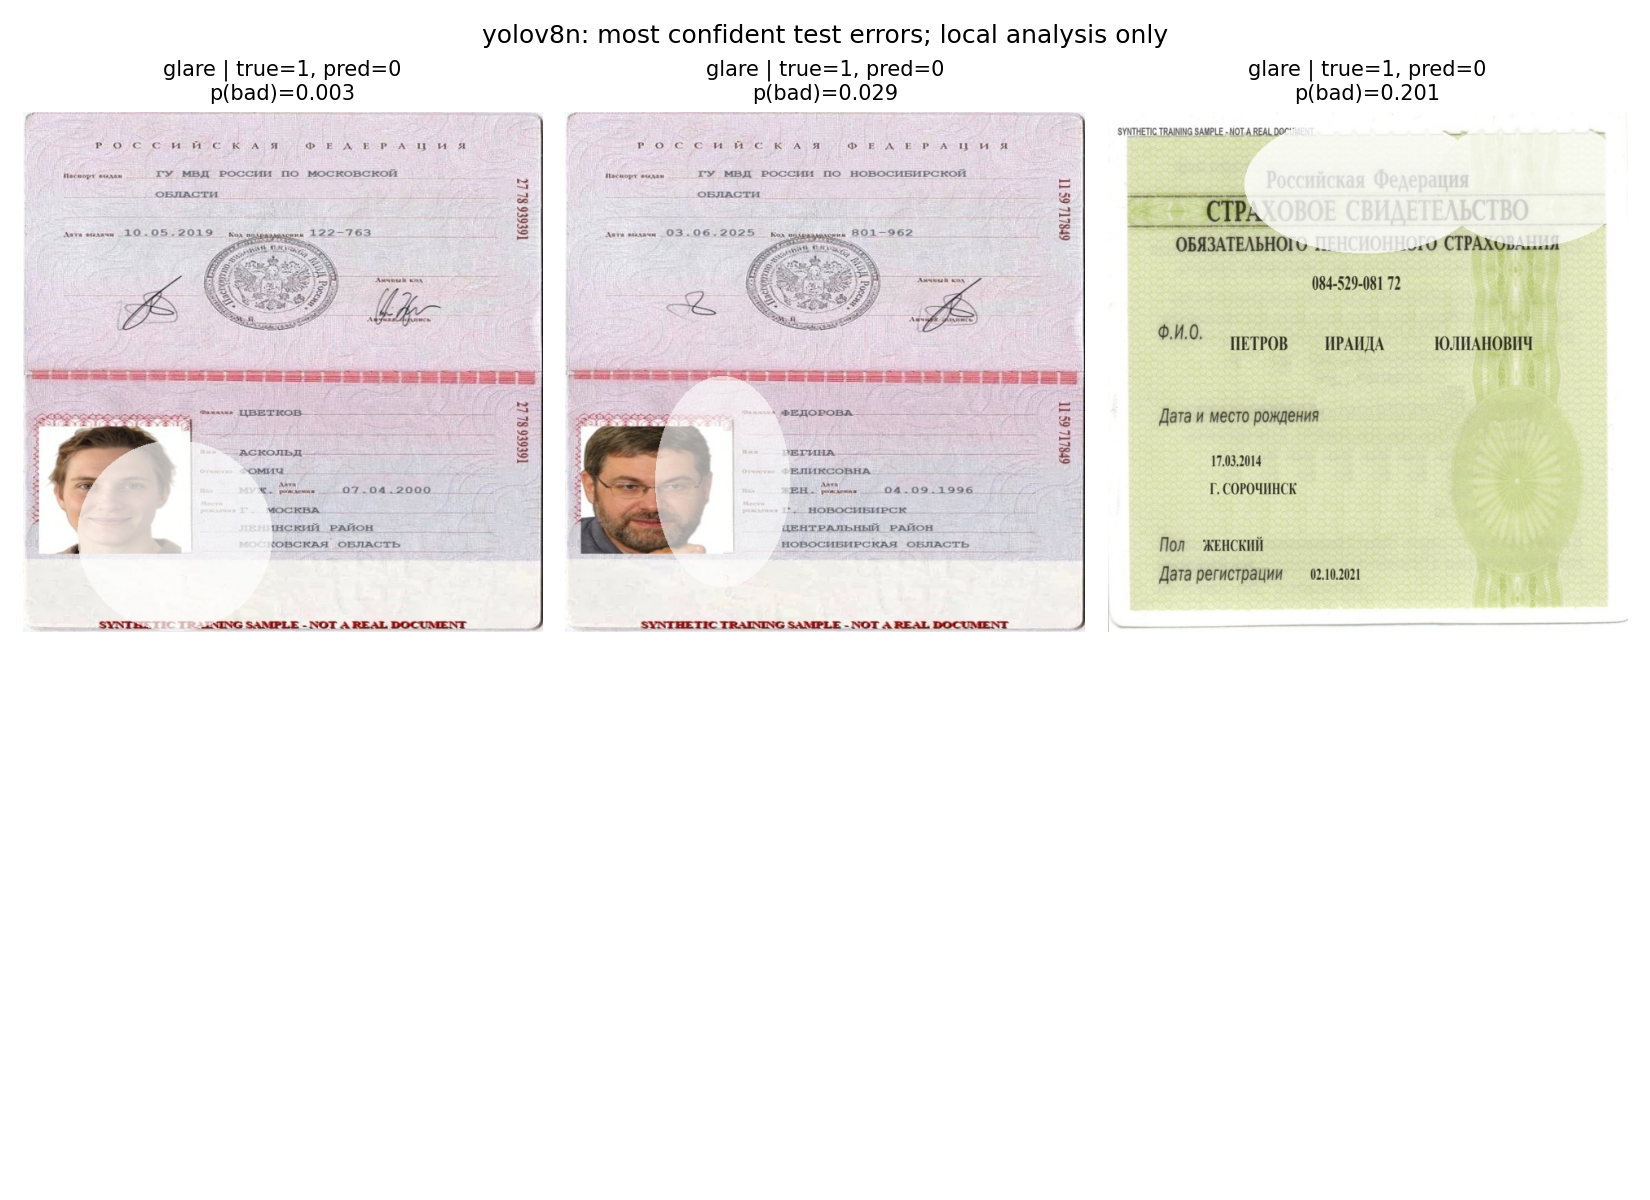

## Conclusion

The predefined rule selects YOLOv8n-cls at 26.97 ms/image and 2.83 MiB. Its test accuracy is 98.89% and bad recall is 97.78%. MobileNetV2 has the highest observed test accuracy, 99.63%, but model selection does not use test rankings. Only 45 independent source documents underlie the test partition. See `results/Final_Report.md` for the full interpretation, alternatives and limitations. Retain the external dataset and original checkpoints for inference reproducibility.